| **Name** | **Family Name** | **Matriculation Number** |
| -------- | --------------- | ------------------------ |
| Marco    | Lorenzato       | 2197529                  |
| Kevin    | Brugnera        | 2196578                  |
| Nicolò   | Teneggi         | 2195476                  |
| Polina   | Gridiaeva       | 2186171                  |


# XGBoost (XGB) 

Study the data in the file `x_XGB_26.dat` (N=5000 samples) with labels `y_XGB_26.dat`.  

The dataset should be split into $N’$ training samples and $N’’$ validation samples, with $N’+N’’=N$.


<div style="text-align: center;">
    <img src="img.png" width="600"/>
</div>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
# AdaBoost Algorithm
from sklearn.ensemble import AdaBoostClassifier
# Gradient Boosting 
from sklearn.ensemble import GradientBoostingClassifier
# XGBoost
import xgboost
from xgboost import XGBClassifier
from xgboost import plot_importance, to_graphviz, plot_tree
from IPython.display import display, Markdown
print("XGBoost version:",xgboost.__version__)

from keras.models import Sequential
from keras.layers import Dense, Dropout, Input
from keras import optimizers
import keras_tuner
from keras.callbacks import EarlyStopping

mycmap = "winter"
mpl.rcParams['image.cmap'] = mycmap
plt.rcParams['font.size'] = 13

In [2]:
np.random.seed(12345)
# random seed for reproducibility
# splitting dataset into training and validation
dname="./DATA/"
str0="_XGB_26.dat"
fnamex=dname+'x'+str0
fnamey=dname+'y'+str0
x = np.loadtxt(fnamex, delimiter=" ",dtype=float)
y = np.loadtxt(fnamey)
y = y.astype(int)
N,L = len(x), len(x[0])

N_train = int(0.75*N)
x_train,y_train = x[:N_train],y[:N_train]
x_test,y_test = x[N_train:],y[N_train:]
print(f"N={N}, N_train={N_train}, L={L}")
print(x.shape)

N=5000, N_train=3750, L=4
(5000, 4)


[-31.608 -29.544   6.773   9.554] 0
[46.451 15.318 24.891 15.357] 0
[ 24.771  46.131 -49.161 -39.356] 0
[-20.13   15.641  30.981  37.218] 0
[46.465 22.369 14.248 21.745] 0


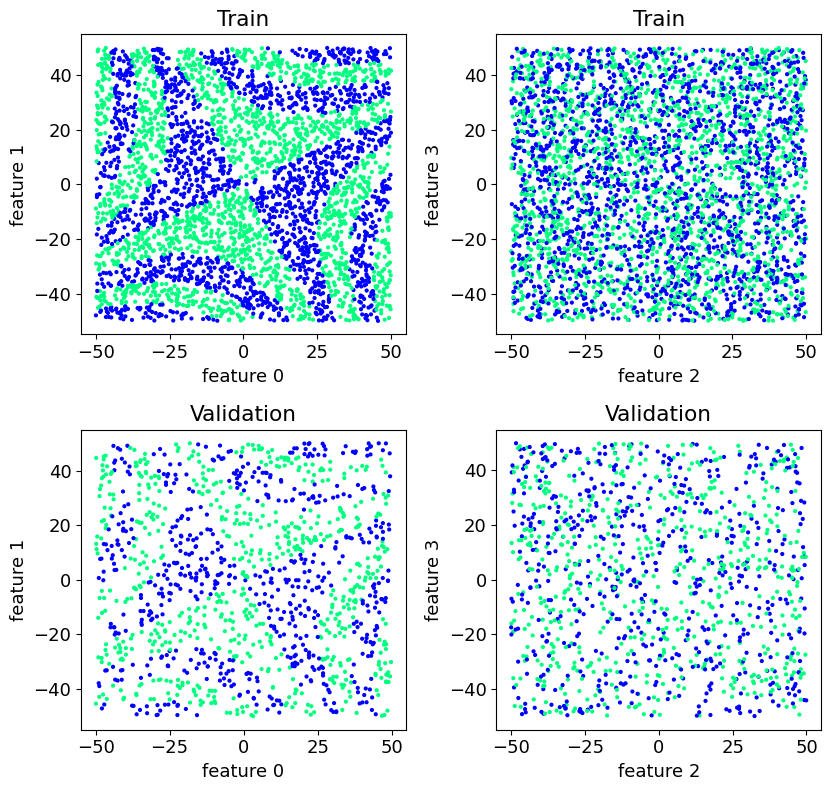

In [3]:
# showing the split data

def scat(ax,x,y,i=0,j=1,s=4,title=""):
    # scatter plot of the data in the plane of features i and j
    ax.scatter(x[:,i],x[:,j],s=s,c=y) 
    ax.set_xlabel(f"feature {i}")
    ax.set_ylabel(f"feature {j}")
    ax.set_title(title)

# print the first 5 data points
for n in range(5):
    print(x[n],y[n])

#print feature plots for the training and test sets
fig,AX = plt.subplots(2,2,figsize=(8.5,8.1))
scat(AX[0,0],x_train,y_train,title="Train")
scat(AX[0,1],x_train,y_train,i=2,j=3,title="Train")
scat(AX[1,0],x_test,y_test,title="Validation")
scat(AX[1,1],x_test,y_test,i=2,j=3,title="Validation")
fig.tight_layout()
plt.show()

---
## 1. Model complexity, parameters and regularization 

Try different parameters (λ, γ, n_estimators, …).   
Which is the simplest yet effective XGB model that keeps a good validation accuracy? Is regularization useful for this analysis?

In [4]:
def classify(clf=GradientBoostingClassifier(),show=False, plot=True, p = True):
    # GradientBoostingClassifier():
    #   n_estimators = 100 (default)
    #   loss function = deviance(default) used in Logistic Regression
    # XGBClassifier()
    #   n_estimators = 100 (default)
    #   max_depth = 3 (default?)
    
    clf.fit(x_train,y_train) # train the model on the training set
    y_hat = clf.predict(x_test) # predict the labels of the test set

    
    accuracy = clf.score(x_test, y_test)

    S=50 # size of the square grid
    dx = 1
    x_seq=np.arange(-S,S+dx,dx) # sequence of points for the grid
    nx = len(x_seq)
    x_plot=np.zeros((nx*nx,L)) # grid of points

    if p:
        print("errors: {:.2f}%   Accuracy={:.3f}".format(100*(1-clf.score(x_test, y_test)),clf.score(x_test, y_test)))
        print('shape of x_plot=',x_plot.shape)
        
    q=0
    for i in range(nx):
        for j in range(nx):
            x_plot[q,:2] = [x_seq[i],x_seq[j]] # only the first two features are used for the artificial grid
            q+=1
    y_plot= clf.predict(x_plot) # predict the labels of the grid points

    if plot:
        fig,AX = plt.subplots(1,2,figsize=(8.2,4))
        scat(AX[0],x_plot[:],y_plot,s=dx,title="predicted")
        scat(AX[1],x_train[:],y_train,title="training set")
        fig.tight_layout()
        plt.show()
    
    if show:      
        dump_list = clf.get_booster().get_dump() # get the list of trees in the model
        num_trees = len(dump_list)
        print("num_trees=",num_trees)
        
        fig, AX = plt.subplots(2,1,figsize=(12, 5))
        for i in range(min(2,num_trees)):
            ax=AX[i]
            plot_tree(clf, tree_idx=i, ax=ax)
        fig.savefig("DATA/tree-classif.png", dpi=400, pad_inches=0.02)   
        plt.show()
    return accuracy

In [5]:
import itertools

learning_rates = [0.2, 0.4, 0.6, 0.8, 1]
n_estimators_list = [20, 50, 100, 200, 500]
reg_lambdas = [0.01, 0.1, 1, 10, 100]
gammas = [0.0001, 0.001, 0.01, 0.1, 1]

hps_list=[{"reg_lambda": l, "n_estimators": n, "learning_rate": lr, "gamma": g} for l, n, lr, g in itertools.product(reg_lambdas, n_estimators_list, learning_rates, gammas)]
#print(hps_list)

We define here the cross validation functions, for both the feed-forward NN, which will be implemented later, and for the XGB. The latter will be used to find the best parameters combination among the list created above.

In [6]:
def k_fold_cross_validation(x_train, y_train, n_models: int, k: int, nepoch: int, batch_size: int = 50):

    np.random.seed(123)
    best_perf = 1e20
    best_model = None
    best_hps = None

    hps_list = tuner.get_best_hyperparameters(num_trials=n_models)

    # Fold idxs
    indices = np.arange(len(x_train))
    np.random.shuffle(indices)
    fold_size = len(x_train) // k

    x_folds = []
    y_folds = []
    for i in range(k):
        fold_idx = indices[i * fold_size: (i + 1) * fold_size]
        x_folds.append(x_train[fold_idx])
        y_folds.append(y_train[fold_idx])

    for hps in hps_list:
        model_perf = 0

        for test_idx in range(k):
            model = tuner.hypermodel.build(hps)            
            # Training folds
            x_train_fold = np.concatenate([x for i, x in enumerate(x_folds) if i != test_idx])
            y_train_fold = np.concatenate([y for i, y in enumerate(y_folds) if i != test_idx])
            # Validation fold
            x_val_fold = x_folds[test_idx]
            y_val_fold = y_folds[test_idx]
            # fit and save the score
            fit = model.fit(x_train_fold, y_train_fold,
                            validation_data=(x_val_fold, y_val_fold),
                            epochs=nepoch, batch_size=batch_size, verbose=0)
            model_perf += fit.history['val_loss'][-1]
        model_perf /= k

        if model_perf < best_perf:
            best_perf = model_perf
            best_model = model
            best_hps = hps
            
    return best_hps

# K_fold for XGBoost

def k_fold_XGB(x_train, y_train, hps_list, k=5):
    
    np.random.seed(123)
    indices = np.arange(len(x_train))
    np.random.shuffle(indices)
    
    fold_size = len(x_train) // k
    x_folds = []
    y_folds = []
    for i in range(k):
        fold_idx = indices[i*fold_size:(i+1)*fold_size]
        x_folds.append(x_train[fold_idx])
        y_folds.append(y_train[fold_idx])
    
    best_perf = np.inf
    best_hps = None

    for hps in hps_list:
        fold_loss = 0
        for test_idx in range(k):
            # Train on all folds except test_idx
            x_train_fold = np.concatenate([x for i, x in enumerate(x_folds) if i != test_idx])
            y_train_fold = np.concatenate([y for i, y in enumerate(y_folds) if i != test_idx])
            
            x_val_fold = x_folds[test_idx]
            y_val_fold = y_folds[test_idx]
            
            # Initialize XGBoost
            model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **hps)
            
            # Train the model
            model.fit(x_train_fold, y_train_fold)
            
            # Compute fold val loss (score) 
            fold_loss += 100 * (1 - model.score(x_val_fold, y_val_fold))
        
        fold_loss /= k  # average over folds

        # Save best hyperparameters
        if fold_loss < best_perf:
            best_perf = fold_loss
            best_hps = hps
    
    return best_hps

The best hyperparameters found by the k-fold are:
 {'reg_lambda': 10, 'n_estimators': 200, 'learning_rate': 0.4, 'gamma': 0.001}
errors: 7.44%   Accuracy=0.926
shape of x_plot= (10201, 4)


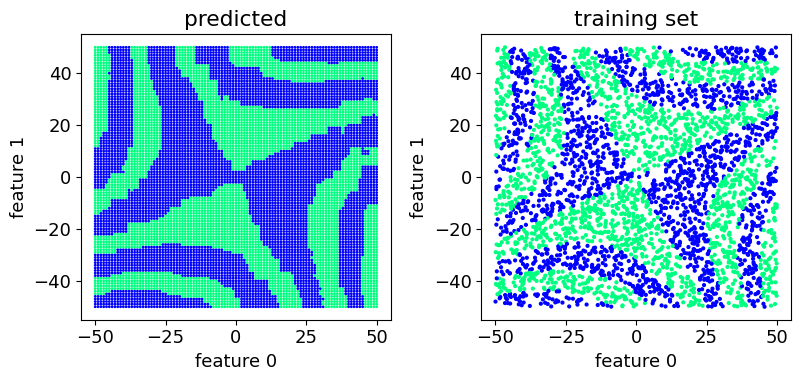

In [7]:
# We can now find the best model and display its predictions on the test set

best_hps = k_fold_XGB(x_train, y_train, hps_list)
print('The best hyperparameters found by the k-fold are:\n', best_hps)
best_model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **best_hps)
baseline = classify(best_model)


We now want to display the behaviour of the accuracy varying one single parameter at a time

In [8]:
accuracies_l = []
hps = best_hps.copy()

for l in reg_lambdas:
    hps['reg_lambda'] = l
    model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **hps)
    accuracies_l.append(classify(model, p=False, plot=False))

accuracies_n = []
hps = best_hps.copy()

for n in n_estimators_list:
    hps['n_estimators'] = n
    model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **hps)
    accuracies_n.append(classify(model, p=False, plot=False))

accuracies_eta = []
hps = best_hps.copy()

for eta in learning_rates:
    hps['learning_rate'] = eta
    model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **hps)
    accuracies_eta.append(classify(model, p=False, plot=False))
    

accuracies_gamma = []
hps = best_hps.copy()

for gamma in gammas:
    hps['gamma'] = gamma
    model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **hps)
    accuracies_gamma.append(classify(model, p=False, plot=False))

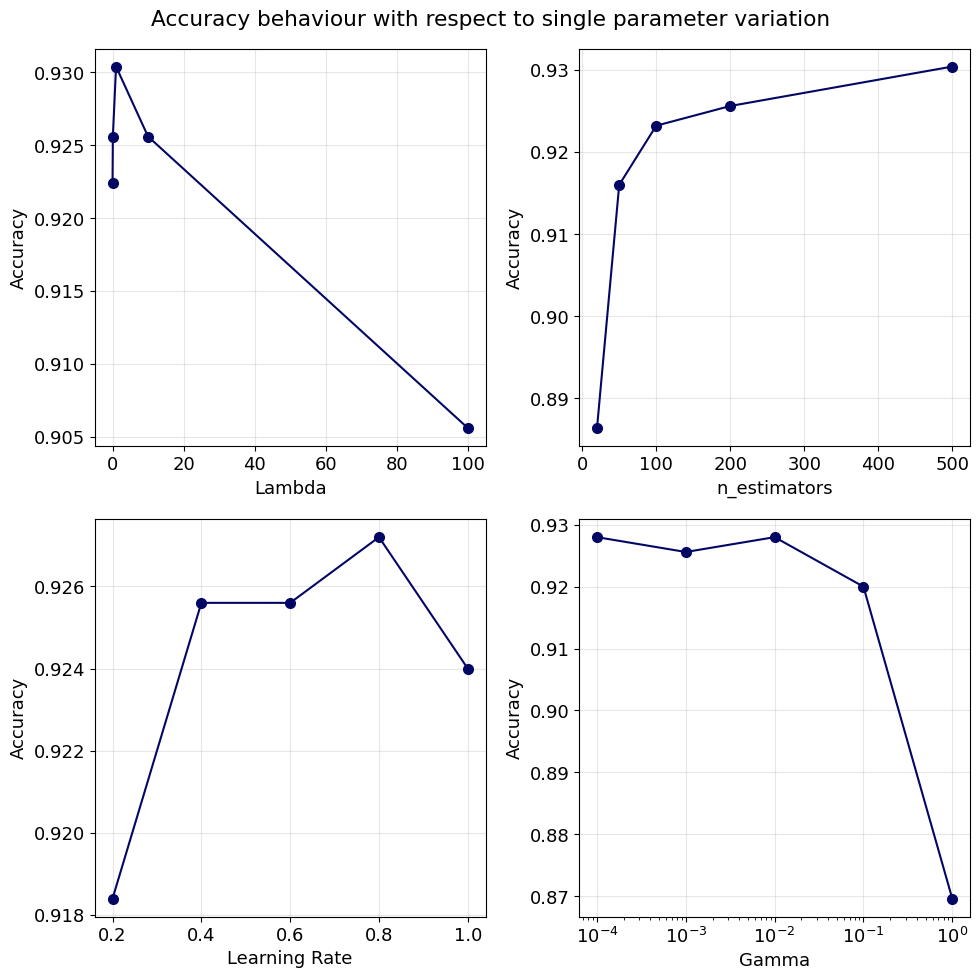

In [9]:
fig, ax = plt.subplots(2, 2, figsize = (10, 10), layout ='tight')

ax[0, 0].plot(reg_lambdas, accuracies_l, marker = 'o', ms=7, color='xkcd:darkblue')
ax[0, 0].set_ylabel('Accuracy')
ax[0, 0].set_xlabel('Lambda')
ax[0, 0].grid(alpha=0.3)

ax[0, 1].plot(n_estimators_list, accuracies_n, marker = 'o', ms=7, color='xkcd:darkblue')
ax[0, 1].set_ylabel('Accuracy')
ax[0, 1].set_xlabel('n_estimators')
ax[0, 1].grid(alpha=0.3)

ax[1, 0].plot(learning_rates, accuracies_eta, marker = 'o', ms=7, color='xkcd:darkblue')
ax[1, 0].set_ylabel('Accuracy')
ax[1, 0].set_xlabel('Learning Rate')
ax[1, 0].grid(alpha=0.3)

ax[1, 1].plot(gammas, accuracies_gamma, marker = 'o', ms=7, color='xkcd:darkblue')
ax[1, 1].set_ylabel('Accuracy')
ax[1, 1].set_xlabel('Gamma')
ax[1, 1].grid(alpha=0.3)
ax[1, 1].set_xscale('log')

fig.suptitle('Accuracy behaviour with respect to single parameter variation')
plt.show()

As we can see, the least important parameter to fix is the number of evaluators, given the vary small variation of the accuracy $(\sim 0.5\%) $ in the considered range; on the other hand, the other hyperparameters play a more important role, generating an improvement in the accuracy of 1-2%. It's also clear that adding regularization to the model improves its performance. It is also to be noted that some particular choices of hyperparameters presented here lead to greater accuracy with respect to the best model found with the folding procedure, but this could simply be an effect of the limited amount of test data, which a particular choice of parameters could represent in a better way, while the folding procedure is built precisely to limit this kind of effects and find the best overall values.

We now show the predictions generated by some other choice of paramteres among the ones used for the comparison.


{'reg_lambda': 0, 'n_estimators': 100, 'learning_rate': 1, 'gamma': 0.5}
errors: 10.80%   Accuracy=0.892
shape of x_plot= (10201, 4)


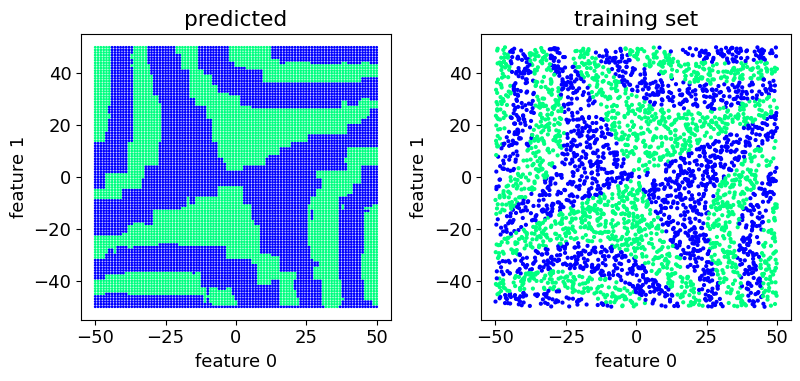

0.892

In [10]:
hps = {'reg_lambda': 0, 'n_estimators':100, 'learning_rate': 1, 'gamma':0.5}
print(hps)
model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **hps)
classify(model)

{'reg_lambda': 0.8, 'n_estimators': 90, 'learning_rate': 0.5, 'gamma': 0.8}
errors: 10.72%   Accuracy=0.893
shape of x_plot= (10201, 4)


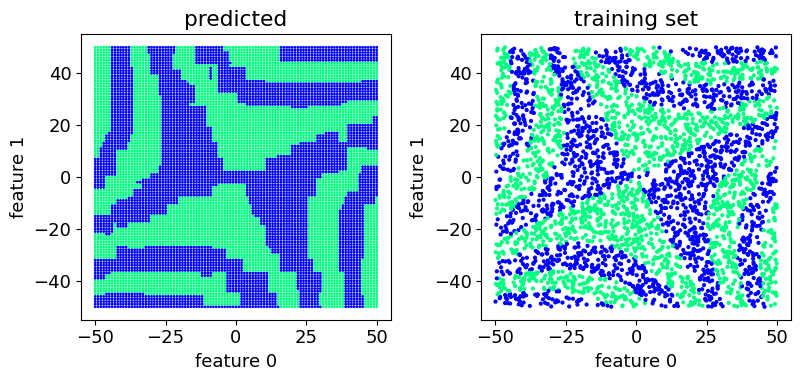

0.8928

In [11]:
hps = {'reg_lambda': 0.8, 'n_estimators':90, 'learning_rate': 0.5, 'gamma':0.8}
print(hps)
model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **hps)
classify(model)

{'reg_lambda': 0.8, 'n_estimators': 80, 'learning_rate': 0.5, 'gamma': 0.1}
errors: 8.64%   Accuracy=0.914
shape of x_plot= (10201, 4)


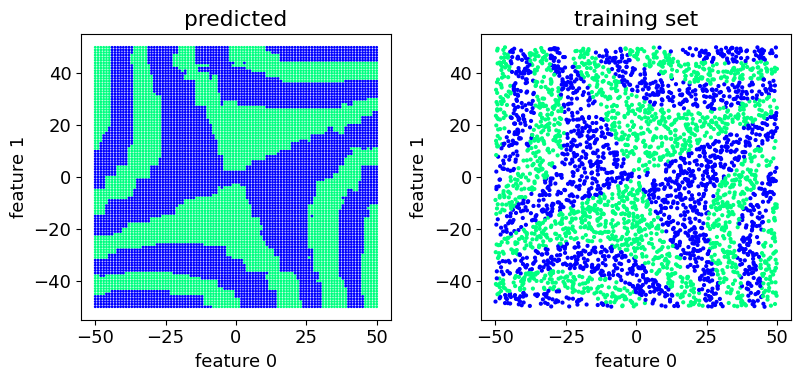

0.9136

In [12]:
hps = {'reg_lambda': 0.8, 'n_estimators':80, 'learning_rate': 0.5, 'gamma':0.1}
print(hps)
model = XGBClassifier(seed=1, objective='binary:logistic', importance_type='gain', **hps)
classify(model)

---
## 2. Dimensionality reduction

Consider reduced data samples with $L' < L$ features. For example, feature $0, 1, 3$ out of the $L = 4$ features.     
Check if the exclusion of the least important feature(s) from training data leads to better accuracy.

Initially, we use the `classify_red` function to classify samples once the model is created. We have modified the `classify` function to allow the exclusion of one feature from the training set.

In [13]:
def classify_red(x_train, y_train, x_test, y_test, clf=GradientBoostingClassifier(), show=False, exclude=False):

    if exclude is False: # by default skips that
        x_train_red, x_test_red = x_train, x_test
    else:
        x_train_red = np.delete(x_train, exclude, axis=1)
        x_test_red = np.delete(x_test, exclude, axis=1)
    
    clf.fit(x_train_red,y_train) # train the model on the training set
    y_hat = clf.predict(x_test_red) # predict the labels of the test set
    
    print("errors: {:.2f}%   Accuracy={:.3f}".format(100*(1-clf.score(x_test_red, y_test)),clf.score(x_test_red, y_test)))
    S=50 # size of the square grid
    dx = 1
    x_seq=np.arange(-S,S+dx,dx) # sequence of points for the grid
    nx = len(x_seq)
    x_plot=np.zeros((nx*nx,x_train_red.shape[1])) # grid of points
    print('shape of x_plot=',x_plot.shape)
    q=0
    for i in range(nx):
        for j in range(nx):
            x_plot[q,:2] = [x_seq[i],x_seq[j]] # only the first two features are used for the artificial grid
            q+=1
    y_plot= clf.predict(x_plot) # predict the labels of the grid points

    fig,AX = plt.subplots(1,2,figsize=(8.2,4))
    scat(AX[0],x_plot[:],y_plot,s=dx,title="predicted")
    scat(AX[1],x_train_red[:],y_train,title="training set")
    fig.tight_layout()
    plt.show()
    
    if show:      
        dump_list = clf.get_booster().get_dump() # get the list of trees in the model
        num_trees = len(dump_list)
        print("num_trees=",num_trees)
        
        fig, AX = plt.subplots(2,1,figsize=(12, 5))
        for i in range(min(2,num_trees)):
            ax=AX[i]
            plot_tree(clf, tree_idx=i, ax=ax)
        fig.savefig("DATA/tree-classif.png", dpi=400, pad_inches=0.02)   
        plt.show()
    
    return clf.score(x_test_red, y_test)

We then loop over the features, excluding one feature at a time, to determine which feature is most advantageous to drop.
The training is done with the best model found at point 1.

## Feature 0 excluded

errors: 41.52%   Accuracy=0.585
shape of x_plot= (10201, 3)


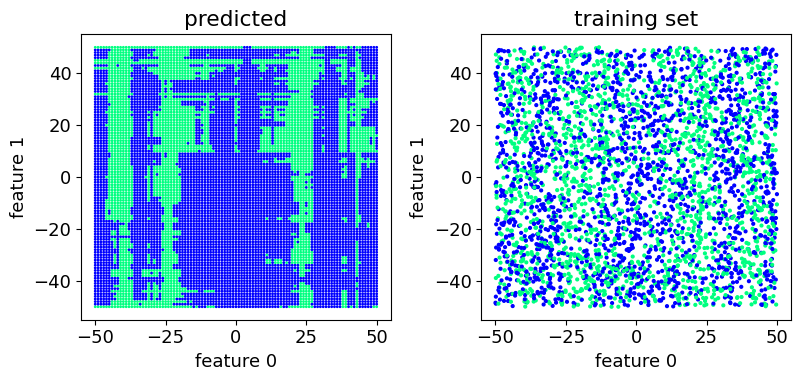

## Feature 1 excluded

errors: 41.92%   Accuracy=0.581
shape of x_plot= (10201, 3)


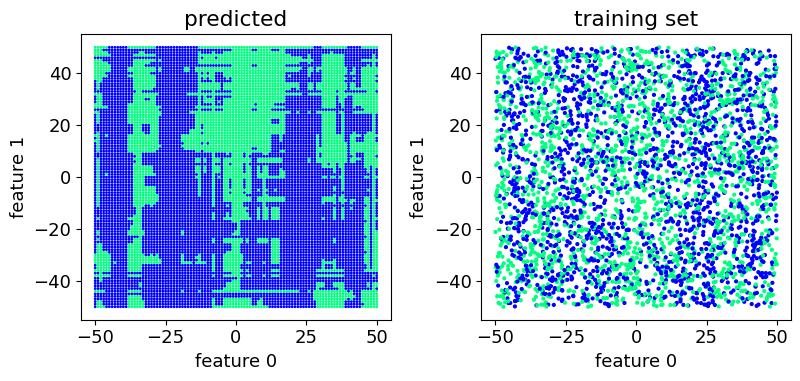

## Feature 2 excluded

errors: 6.80%   Accuracy=0.932
shape of x_plot= (10201, 3)


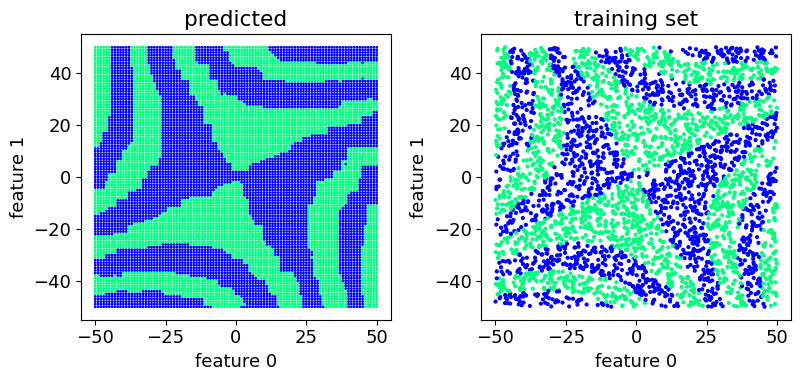

## Feature 3 excluded

errors: 6.72%   Accuracy=0.933
shape of x_plot= (10201, 3)


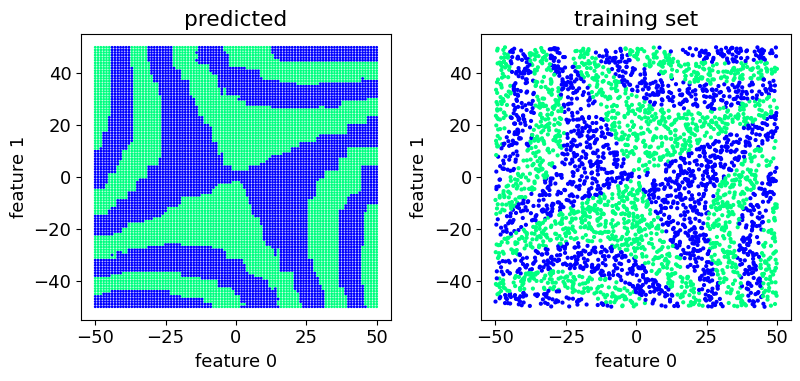

In [14]:
from IPython.display import display, Markdown
#best_hps = {"reg_lambda": l, "n_estimators": n, "learning_rate": lr}


scores = [baseline]
labels = ['Full dataset']
for feature in range(4):
    display(Markdown(f"## Feature {feature} excluded"))
    
    best_model = XGBClassifier(seed=1, objective='binary:logistic', importance_type="gain", **best_hps)
    score = classify_red(x_train, y_train, x_test, y_test, best_model, show=False, exclude=feature)

    scores.append(score)
    labels.append(f'w/o feat. {feature}')

We show the results in the following histogram:

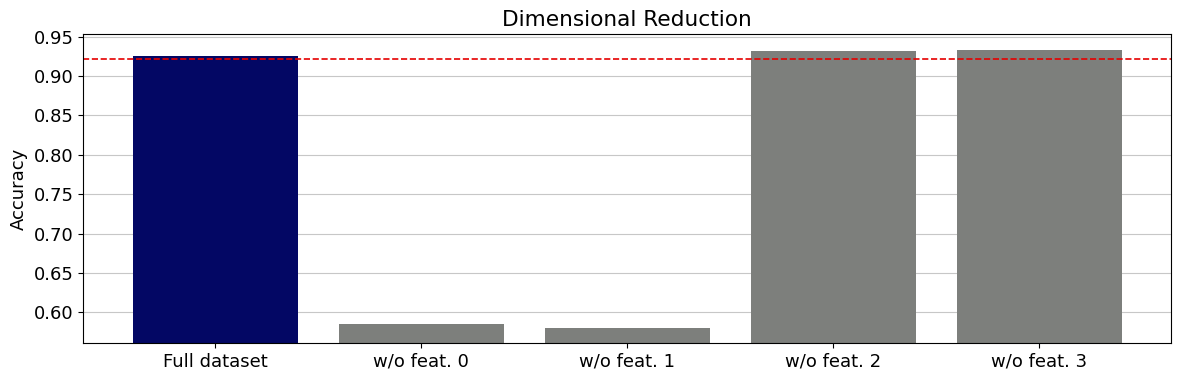

In [15]:
fig, ax = plt.subplots(figsize= (12, 4), layout='tight')

bars = ax.bar(labels, scores, color = ['xkcd:darkblue', 'xkcd:medium grey', 'xkcd:medium grey', 'xkcd:medium grey', 'xkcd:medium grey'], zorder = 2)

ax.set_ylim(min(scores) - 0.02, max(scores) + 0.02)
ax.set_ylabel('Accuracy')
ax.set_title('Dimensional Reduction')

ax.grid(axis='y', alpha=0.7)
ax.axhline(0.922, linestyle = '--', linewidth = 1.2, color = 'xkcd:red')

plt.show()

As it was expected because of the way the data was generated, features 0 and 1 are the only relevant ones, and if we exclude them then the model both the training set and the predictions lose any regularity. Instead, features 2 and 3 can be safely removed, and indeed the accuracy improves by performing this dimensional reduction.

---
## 3. XGBoost vs NN (Feature: 0, 1)

Compare the validation accuracy of XGB with that of a simple feed-forward neural network (FFNN).

- By varying the number of data samples $N'$ in the training set (i.e., reducing the fraction $N' / N$ of the data set used for training)
- With cross-validation for all cases.

We initially define functions to build up our feed-forward neural network.

In [16]:
def build_model(hp):
    model = Sequential()
    act = hp.Choice('activation', ['relu', 'elu', 'sigmoid'])
    opt_name = hp.Choice('optimizer', values=['adam', 'sgd', 'rmsprop'])
    lr = hp.Choice('learning_rate', values=[ 1e-2, 1e-1])
    drop = hp.Choice('dropout', values=[0.0, 0.1, 0.2])

    L = 2 # for the reduced case
    
    model.add(Input(shape=(L,)))
    model.add(Dense(L, activation=act))
    model.add(Dense(20, activation=act))
    model.add(Dropout(drop))
    model.add(Dense(20, activation=act))
    model.add(Dropout(drop))
    model.add(Dense(20, activation=act))
    model.add(Dropout(drop))
    model.add(Dense(1, activation='sigmoid'))
    
    opt = optimizers.get(opt_name)
    opt.learning_rate = lr

    model.compile(optimizer=opt, 
                  loss='binary_crossentropy', 
                  metrics=['accuracy'])
    return model

**OBSERVATION**

Based on the previous analysis, features 2 and 3 were identified as predominantly noisy. 
XGBoost showed improved performance when these features were excluded. To ensure a fair comparison and to prevent the neural network (NN) from learning from noisy inputs—which previously led to a degradation in overall performance—we restrict the feature space to only x₀ and x₁.
As specified in the title, the following comparison is therefore conducted using only these two features.


To optimize the NN, we employ Random Search to identify the best hyperparameters on the training set. 
We then consider different fractions of the dataset to evaluate how performance scales with the amount of training data, comparing the NN against the XGBoost algorithm.

Finally, for each fraction, we apply cross-validation to select the best-performing neural network configuration.

In [17]:
fractions = [0.5, 0.6, 0.7, 0.8, 0.9]

learning_rates = [0.4, 0.6, 0.8]
n_estimators_list = [50, 100, 200]
reg_lambdas = [1, 10, 100]
gammas = [0.0001, 0.001, 0.01]

hps_list=[{"reg_lambda": l, "n_estimators": n, "learning_rate": lr, "gamma": g} for l, n, lr, g in itertools.product(reg_lambdas, n_estimators_list, learning_rates, gammas)]
#print(hps_list)

To perform cross-validation on XGBoost, we first need to define a list of hyperparameter sets to test. Each set specifies values for parameters such as `reg_lambda`, `gamma`, and `n_estimators`, which will be evaluated across the k folds to find the best configuration.

### FFNN vs XGBoost (N' / N = 0.5)

E0000 00:00:1774544015.272146  206602 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Best hyperparameters of NN found for (N' / N = 0.5): 

  activation: relu
  optimizer: adam
  learning_rate: 0.01
  dropout: 0.0

 XGBoost: Error and Accuracy
errors: 7.36%   Accuracy=0.926
shape of x_plot= (10201, 2)


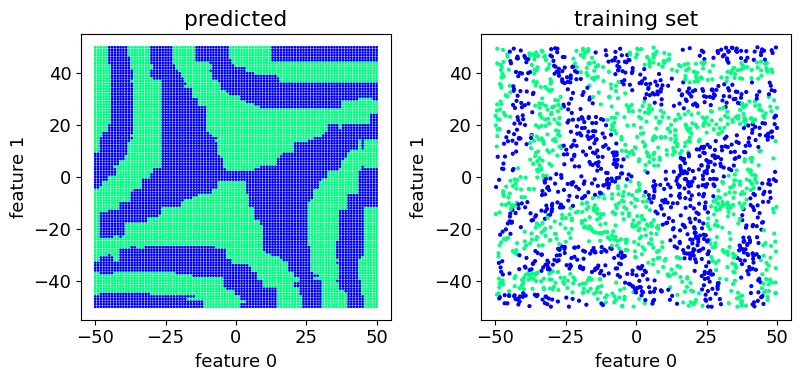

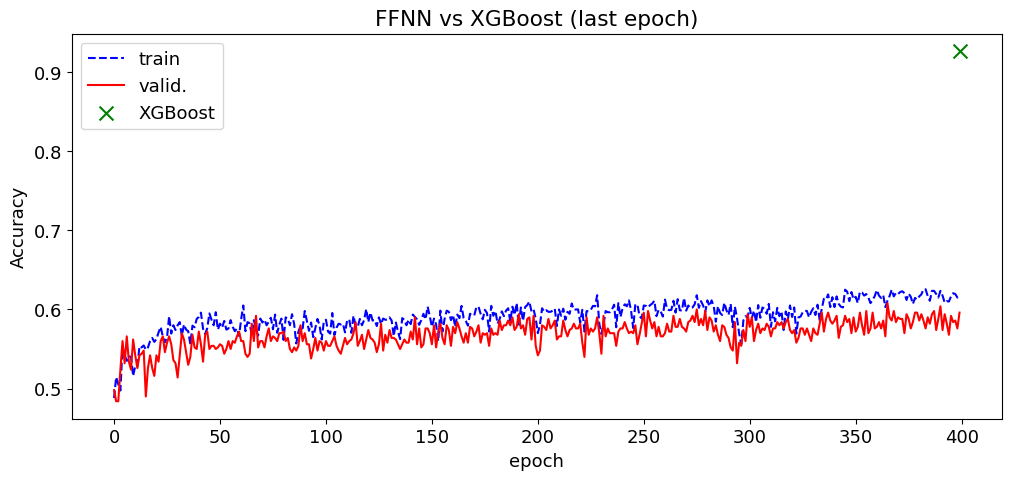

### FFNN vs XGBoost (N' / N = 0.6)

Best hyperparameters of NN found for (N' / N = 0.6): 

  activation: elu
  optimizer: adam
  learning_rate: 0.01
  dropout: 0.0

 XGBoost: Error and Accuracy
errors: 8.00%   Accuracy=0.920
shape of x_plot= (10201, 2)


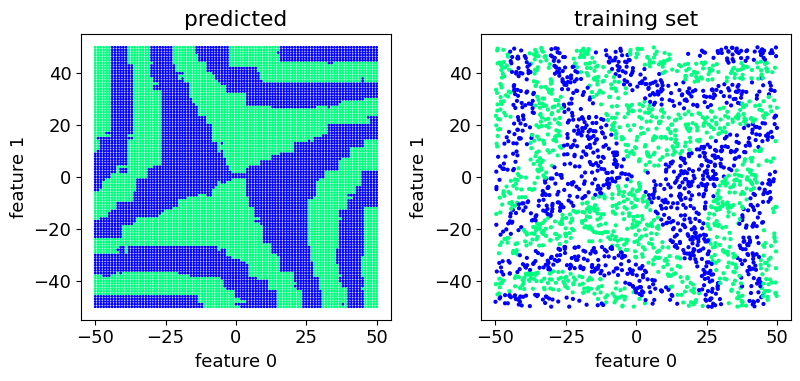

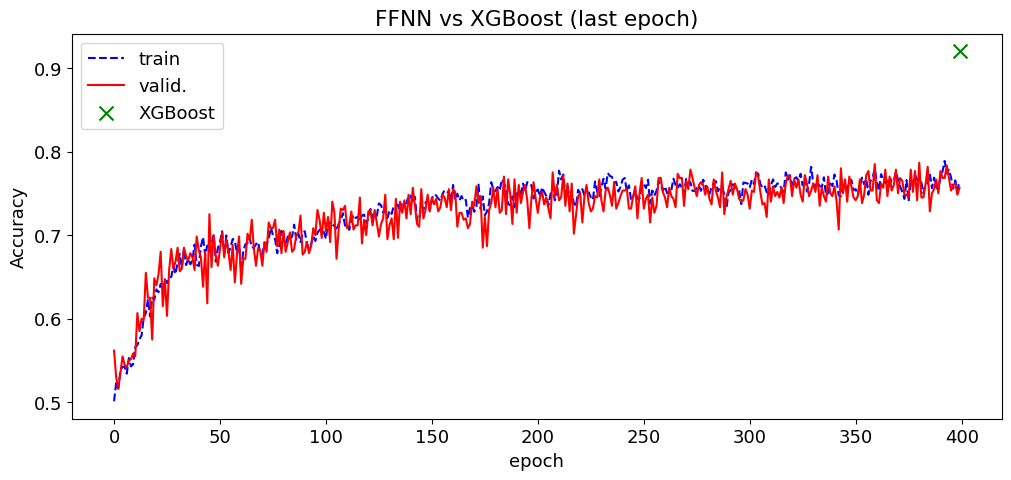

### FFNN vs XGBoost (N' / N = 0.7)

Best hyperparameters of NN found for (N' / N = 0.7): 

  activation: elu
  optimizer: sgd
  learning_rate: 0.1
  dropout: 0.0

 XGBoost: Error and Accuracy
errors: 7.60%   Accuracy=0.924
shape of x_plot= (10201, 2)


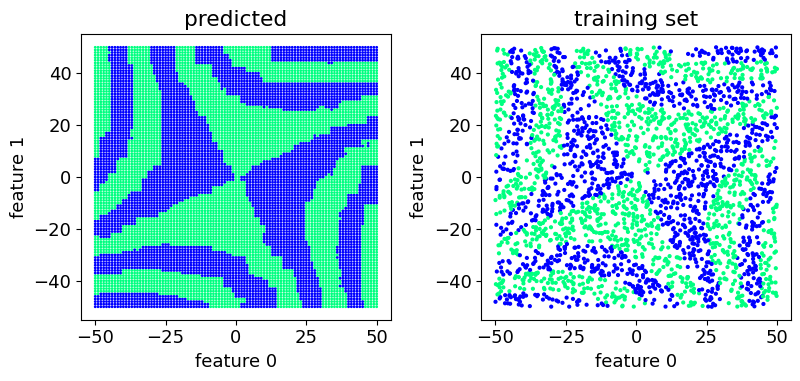

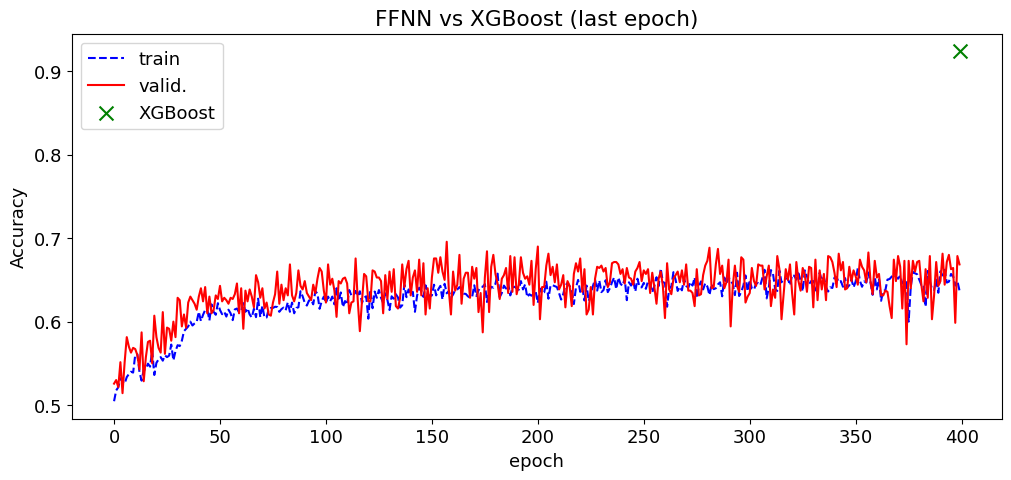

### FFNN vs XGBoost (N' / N = 0.8)

Best hyperparameters of NN found for (N' / N = 0.8): 

  activation: elu
  optimizer: rmsprop
  learning_rate: 0.01
  dropout: 0.1

 XGBoost: Error and Accuracy
errors: 6.60%   Accuracy=0.934
shape of x_plot= (10201, 2)


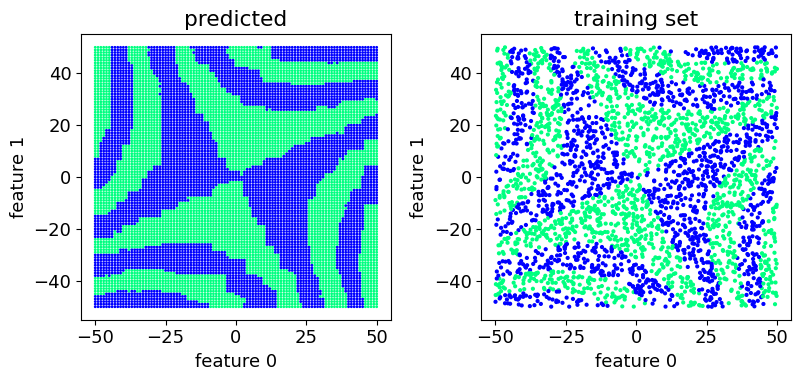

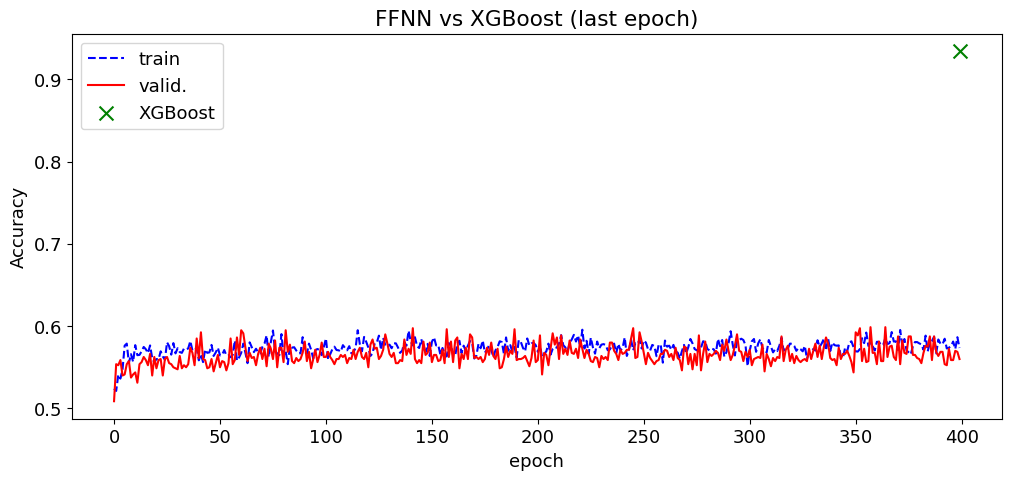

### FFNN vs XGBoost (N' / N = 0.9)

Best hyperparameters of NN found for (N' / N = 0.9): 

  activation: elu
  optimizer: adam
  learning_rate: 0.01
  dropout: 0.2

 XGBoost: Error and Accuracy
errors: 5.20%   Accuracy=0.948
shape of x_plot= (10201, 2)


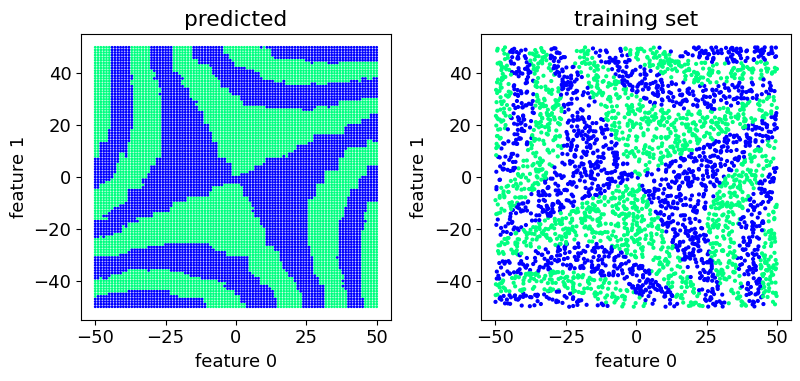

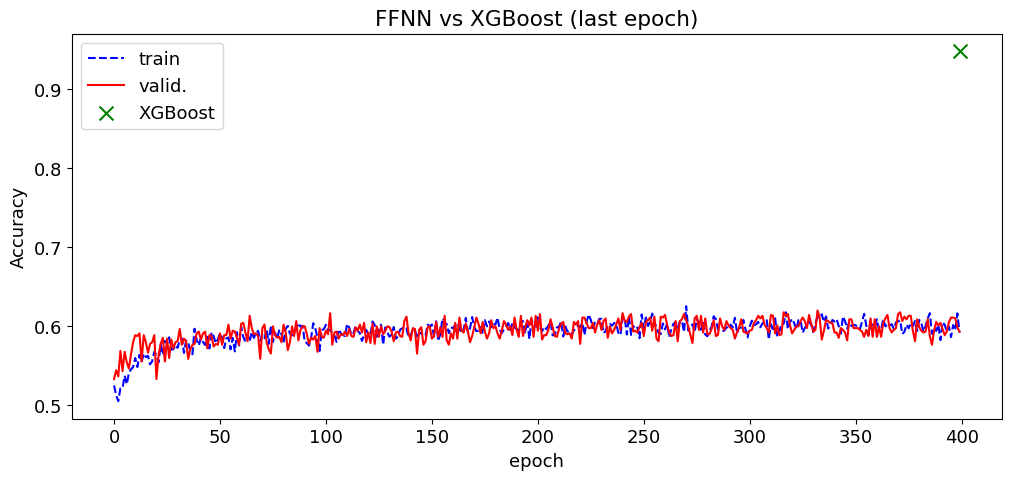

In [18]:
x_red = x[:, [0, 1]] # reduction of the dimension of the training set 

xgb_acc = []
nn_last_acc = []

for frac in fractions:

    display(Markdown(f"### FFNN vs XGBoost (N' / N = {frac})"))

    # select the fraction
    N_train = int(frac * x_red.shape[0])
    x_train_full, y_train_full = x_red[:N_train].copy(), y[:N_train].copy()
    x_test, y_test = x_red[N_train:].copy(), y[N_train:].copy()

    val_fraction = 0.2
    N_val = int(val_fraction * len(x_train_full))

    x_valid, y_valid = x_train_full[:N_val], y_train_full[:N_val]
    x_train, y_train = x_train_full[N_val:], y_train_full[N_val:]

    # build up the model tuning the best params each time we discard a feature
    stop_early = EarlyStopping( monitor='val_loss', patience=10, min_delta=0.0005, restore_best_weights=True)
    tuner = keras_tuner.RandomSearch(hypermodel=build_model, objective="val_loss", max_trials=10, executions_per_trial=1,
        overwrite=True, directory='./RandomSearch', project_name=f'randomSearch_{frac}')
    tuner.search(x_train, y_train, epochs=100, batch_size=200, validation_data=(x_valid, y_valid), callbacks=[stop_early], verbose=0)
    best_hps = k_fold_cross_validation(x_train, y_train, n_models=2, k=4, nepoch=100, batch_size=200)
    print(f"Best hyperparameters of NN found for (N' / N = {frac}): \n")
    for key, value in best_hps.values.items():
        print(f"  {key}: {value}")
    
    # fit NN
    best_model = tuner.hypermodel.build(best_hps)
    fit = best_model.fit(x_train, y_train, epochs=400, batch_size=200, validation_data=(x_valid, y_valid), verbose=0)
    test_loss, test_acc = best_model.evaluate(x_test, y_test, verbose=0)
    nn_last_acc.append(test_acc)

    # fit XGBoost
    print("\n XGBoost: Error and Accuracy")
    best_hps = k_fold_XGB(x_train, y_train, hps_list, k=4)
    best_model_XGB = XGBClassifier(seed=1, objective='binary:logistic', importance_type="gain", **best_hps)
    acc = classify_red(x_train, y_train, x_test, y_test, best_model_XGB)
    xgb_acc.append(acc)

    # PLOT
    fig, ax = plt.subplots(figsize=(12,5))
    ax.plot(fit.history['accuracy'], label="train", c="b", ls="--")
    ax.plot(fit.history['val_accuracy'], label="valid.", c="r")
    ax.scatter(len(fit.history['val_accuracy'])-1, acc, c='g', marker='x', s=100, label="XGBoost")
    ax.set_title("FFNN vs XGBoost (last epoch)")
    ax.set_xlabel('epoch')
    ax.set_ylabel("Accuracy")
    ax.legend()
    plt.show()

### 3.1 Conclusions

In this section, we compare the performance of the FFNN and XGBoost models using different fractions of the dataset for training.  
We report a table showing the test accuracies for each fraction and each model.  
Additionally, a plot is provided to visualize the accuracy trends across the different fractions.

In [19]:
import pandas as pd

df_acc = pd.DataFrame({'Fraction': fractions, 'FFNN Accuracy': nn_last_acc,'XGBoost Accuracy': xgb_acc}).round(3)
df_acc

,Fraction,FFNN Accuracy,XGBoost Accuracy
0,0.5,0.594,0.926
1,0.6,0.778,0.920
2,0.7,0.688,0.924
3,0.8,0.544,0.934
4,0.9,0.590,0.948


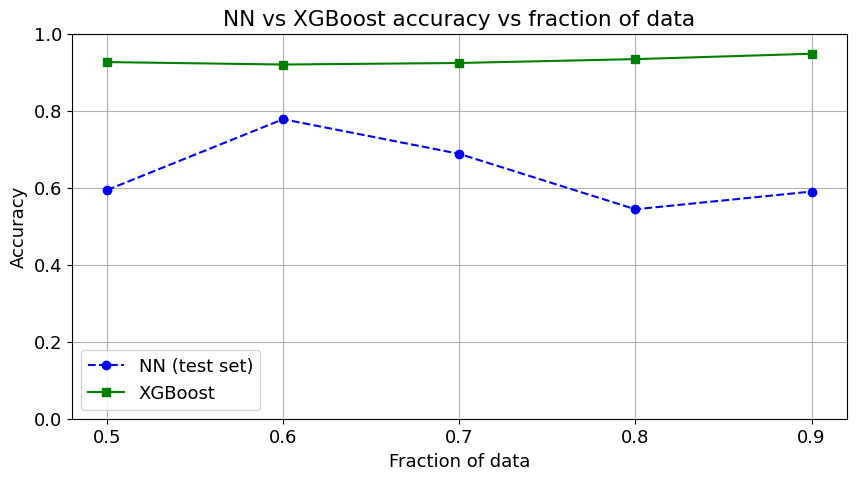

In [20]:
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(fractions, nn_last_acc, marker='o', linestyle='--', color='b', label="NN (test set)")
ax.plot(fractions, xgb_acc, marker='s', linestyle='-', color='g', label="XGBoost")
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9])
ax.set_ylim(0, 1)
ax.set_xlabel("Fraction of data")
ax.set_ylabel("Accuracy")
ax.set_title("NN vs XGBoost accuracy vs fraction of data")
ax.legend()
ax.grid(True)
plt.show()

We observe that the Feedforward Neural Network (FFNN) performs better when trained on smaller fractions of the dataset. This behavior persists even when the dataset size increases and less relevant features are removed.

A plausible explanation is the inefficiency of the hyperparameter optimization process. In particular, Random Search becomes less effective as the dataset grows, making it harder to identify well-performing configurations for the FFNN.

In contrast, XGBoost consistently achieves better performance across experiments. This suggests that, for the given dataset size and feature space, boosting methods are more suitable and robust.

While neural networks are universal function approximators, their performance in this context is likely limited by insufficient computational resources, suboptimal architecture (e.g., number of layers), and incomplete hyperparameter tuning.

For this specific problem, XGBoost represents the most effective solution, given the current dataset size and optimization setup.

---